# Homework 5: LLM Fine-tuning with Transformers

In this homework you will be **finetuning a small instruction-tuned Language Model (LLM) to do well on previous 189 exam problems while maintaining its general knowledge capabilities.** We will be evaluating you on a hidden test set containing 189 exam problems and general knowledge questions, all in multiple choice format.

We will walk you through how to fine-tune on custom datasets using the standard Hugging Face `transformers` and `trl` libraries.

In this notebook, we use **Qwen/Qwen2.5-0.5B-Instruct**. This is a small but capable model (0.5 billion parameters) that fits easily on most GPUs and trains quickly, allowing us to perform **full fine-tuning** (updating all weights) rather than needing parameter-efficient methods like LoRA (although you are welcome to use LoRA instead).

In this notebook, we provide a small subset of CS189 Exam Questions for you to test and a walkthrough of a simple finetuning pipeline. The actual test set you would be making predictions will be a mix of different questions (Full details are provided in the accompanying PDF)

## Overview
Your task is to:
1. **Adapt the provided notebook**
2. **Generate predictions** on the private test questions (test.csv)
3. **Submit** your results to Kaggle  

**Kaggle competition link:**  
https://www.kaggle.com/t/11c8ffdc967fe3f27755cde6fb5810e8

---
### Rules

You are encouraged to improve the model's performance!

**What you CAN change:**
- **Parsing Logic:** You can improve `parse_choice_from_boxed` to handle more edge cases or different output formats.
- **Training and Testing Data:** You can mix in additional datasets to the training set and build your own eval sets to test if your model is overfitting.
- **Test-Time Adaptations:** You can try different decoding strategies, majority voting, or other inference-time techniques.
- **Prompt Engineering:** You can experiment with Chain-of-Thought (CoT) prompting or different system prompts during inference.

**What you CANNOT change:**
- **The Model:** You must train the `Qwen/Qwen2.5-0.5B-Instruct` model. Do not switch to a different model architecture or size.
- **Colab Compatibility:** Your final notebook must be runnable in Google Colab. Do not add dependencies or steps that break this compatibility.

#### Evaluation

**Important:** Your model will be evaluated on a hidden test set containing both:
1.  **CS189 Exam Problems:** Similar to the ones in your training set.
2.  **General Knowledge Questions:** To check if the model has retained its general capabilities.

**Catastrophic Forgetting:**
As shown in the paper you read for this homework, fine-tuning on a narrow dataset (e.g. just CS189 MCQs) can sometimes cause the model to "forget" how to answer general questions or lose its reasoning abilities.

**Recommendation:**
We strongly encourage you to build your own **test set** that includes both domain-specific and general knowledge questions. Use this to monitor your model's performance and ensure it isn't suffering from catastrophic forgetting. You might want to mix in some general datasets during training or use early stopping to prevent this (the paper you read will be useful here).

---
## The Finetuning Pipeline

Now let's walk through a simple finetuning pipeline using the Hugging Face `transformers` and `trl` libraries. Even though we are using a smaller model, the core structure of the finetuning pipeline follows the classic **ML Lifecycle** covered in lecture!

<img src="https://i.imgur.com/ya2hBEk.png" width="60%">

---

## Learning Problem (P)

**Goal:** Decide what behavior we want the LLM to learn, and from what data.

We want to fine-tune our base Qwen model to better perform on CS189-style multiple choice questions. Our objective is to minimize cross-entropy loss on a dataset of these questions.

Concretely, we will:
- **Load the CS189 MCQ dataset:** A CSV file containing questions, options (A-E), and the correct answer.
- **Format the data:** Convert each row into a "chat" format that the model understands.
  - User: The question + options.
  - Assistant: The correct answer (e.g., `\boxed{A}`).

---
## Model Design (L)

**Goal:** Decide which model we use and how we adapt it.

We use **Qwen/Qwen2.5-0.5B-Instruct**.
- **Architecture:** A Transformer-based Causal Language Model.
- **Adaptation:** We use **Full Fine-tuning**. Since the model is small, we can update all parameters. This differs from "LoRA" (Low-Rank Adaptation) which is often used for larger models (7B+) to save memory.

---
## Optimization (M)

**Goal:** Train the model on the dataset by minimizing loss.

We use TRL’s `SFTTrainer` (Supervised Fine-Tuning Trainer) to perform gradient-based optimization:
- **Loss function:** Standard token-level cross-entropy loss.
- **Optimizer:** AdamW (8-bit version to save some memory, though standard AdamW may also fit depending on your GPU).
- **Hyperparameters:** Learning rate, batch size, etc.

---
## Predict & Evaluate (O)

**Goal:** Check whether the fine-tuned model behaves as desired.

After training, we:
- **Run inference:** Ask the model to answer the MCQs.
- **Compute accuracy:** Check if the model's output (parsed from `\boxed{X}`) matches the ground truth.
- **Compare:** We measure accuracy *before* and *after* fine-tuning to quantify improvement.

---
## Part 0: Environment Setup

This cell installs and imports the required libraries.

In [ ]:
import sys
IS_COLAB = 'google.colab' in sys.modules
if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    %cd /content/drive/MyDrive/cs189/hw/hw5
    ! pip install -q transformers==4.57.2 accelerate datasets trl bitsandbytes

In [3]:
import os
import re
import math
import pandas as pd
import torch
from datasets import Dataset, concatenate_datasets, load_dataset, load_from_disk
from trl import SFTTrainer, SFTConfig
from transformers import AutoModelForCausalLM, AutoTokenizer

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
#MAKE SURE YOU ARE USING GPU
print('Using device:', device)

Using device: cuda


---
## Part 1: Configuration & Model Loading

Here we define all our settings and load the base model.

**Model Design (L):** We select `Qwen/Qwen2.5-0.5B-Instruct`.

In [4]:
# ============================================================================
# === CONFIGURATION - ALL SETTINGS IN ONE PLACE ===
# ============================================================================

# --- Model Configuration ---
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct" # YOU CANNOT CHANGE THIS

# --- Dataset Configuration ---
#TODO: REPLACE WITH YOUR OWN PATH
MCQ_CSV_PATH = "hw5_sample_eval.csv"  # Path to CS189 MCQ sample eval dataset

# --- Training Configuration (feel free to adjust!) ---
TRAIN_BATCH_SIZE = 4
GRADIENT_ACCUMULATION_STEPS = 4
WARMUP_RATIO = 0.03
WEIGHT_DECAY = 0.01
LR_SCHEDULER_TYPE = "cosine"
OPTIM = "adamw_8bit"  # requires bitsandbytes
SEED = 189

# --- Evaluation Configuration ---
EVAL_MAX_NEW_TOKENS = 1024  # How many tokens to generate for inference
OUTPUT_DIR = "./mcq_finetuned_model"

In [6]:
# === Load base model & tokenizer ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# Ensure we have a pad token for training
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None,
)
model.resize_token_embeddings(len(tokenizer))
model.to(device)
model.eval()
print('Model loaded.')

Model loaded.


---
## Part 2: Data Preparation

**Learning Problem (P):** We need to format our raw CSV data into training examples.

We define helper functions to:
1.  Load the CSV.
2.  Build a "prompt" (Question + Options).
3.  Build the full "SFT text" (Prompt + Answer) using the model's chat template.

In [13]:
# === MCQ helpers ===
LETTER_SET = set(list("ABCDE"))

def load_mcq_dataset(csv_path: str = MCQ_CSV_PATH):
    """Load the CS189 MCQ dataset.

    Expected columns:
        - question
        - A, B, C, D, E
        - answer (single letter A-E)
    """
    df = pd.read_csv(csv_path)
    required = ["question", "A", "B", "C", "D", "E", "answer"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Missing required columns in MCQ CSV: {missing}")

    df = df.copy()
    df["answer"] = (
        df["answer"]
        .astype(str)
        .str.strip()
        .str.upper()
    )
    df = df[df["answer"].isin(LETTER_SET)].reset_index(drop=True)
    return df

def build_mcq_prompt(row):
    """Prompt for inference: instruction + question + options.

    The model is expected to answer with the correct letter in \\boxed{} format.
    """
    q = str(row["question"]).strip()
    options = "\n".join([
        f"A. {row['A']}",
        f"B. {row['B']}",
        f"C. {row['C']}",
        f"D. {row['D']}",
        f"E. {row['E']}",
    ])
    prompt = (
        "You are an expert in Machine Learning, Mathematics, and Common Sense reasoning.\n"
        "Your task is to solve the following multiple-choice question systematically.\n\n"
        "Instructions:\n"
        "1. Analyze the Question: Understand the core concept and what is being asked.\n"
        "2. Evaluate Options: Briefly analyze each option to determine why it is correct or incorrect.\n"
        "3. Step-by-Step Reasoning: Think through the logic step-by-step before deciding.\n"
        "4. Final Answer: Output the final answer choice inside a LaTeX box (e.g., \\boxed{A}).\n\n"
        f"Question:\n{q}\n\n"
        f"Options:\n{options}\n\n"
        "Let's think step by step.\n"
        "Reasoning:"
    )
    return prompt

### Understanding the Chat Format (OpenAI Style)

To fine-tune a chat model, we need to structure our data as a conversation. This is often called the **OpenAI Chat Format** or **Messages Format**.

Instead of a single string of text, each example is a list of dictionaries, where each dictionary represents a message in the conversation:
-   `{"role": "user", "content": "..."}`: The input prompt or question.
-   `{"role": "assistant", "content": "..."}`: The model's desired response.

For our MCQ task, we structure it as:
1.  **User**: "Choose exactly one correct option... [Question] ... [Options]"
2.  **Assistant**: "\\boxed{A}"

We then use `tokenizer.apply_chat_template()` to convert this structured list into the specific string format that the model expects (e.g., adding special tokens like `<|im_start|>user...<|im_end|>`).

In [14]:
def parse_choice_from_boxed(text: str):
    if not text:
        return "C"

    text_upper = text.upper()

    m = re.search(r"\\boxed\{[^A-E]*([A-E])[^A-E]*\}", text_upper)
    if m:
        return m.group(1)

    answer_patterns = re.findall(
        r"(?:ANSWER|CHOICE|OPTION)\s*:?\s*([A-E])\b",
        text_upper
    )
    if answer_patterns:
        return answer_patterns[-1]

    letters = re.findall(r"\b([A-E])\b", text_upper)
    if letters:
        return letters[-1]

    return "C"

### **Load and Format the (Eval) Dataset**

We load the MCQ dataset and apply the formatting function.
These are sample eval sets we provided. The actual test set you would be making predictions will be a mix of different questions (Full details are provided in the accompanying PDF)

In [15]:
# === Load MCQ CSV (Evaluation Data) ===
try:
    mcq_df = load_mcq_dataset(MCQ_CSV_PATH)
    print(f"Loaded MCQ dataset with {len(mcq_df)} rows from {MCQ_CSV_PATH}.")
except Exception as e:
    mcq_df = None
    print("Error loading MCQ CSV — check MCQ_CSV_PATH.")
    raise e
mcq_df

Loaded MCQ dataset with 25 rows from hw5_sample_eval.csv.


,id,question,A,B,C,D,E,answer
0,mcq_1,Peanut wants to train a model to accurately cl...,High bias.,Low bias.,High variance.,Low variance.,none of the above,A
1,mcq_2,Consider a binary classification data set with...,Close to zero.,Close to 0.1.,Close to 0.5.,Close to 0.9.,Close to one.,C
2,mcq_3,"Again, consider a binary classification data s...","The precision is 0.1, and the recall is 0.9.","The precision is 0.9, and the recall is 0.1.","The precision is 1.0, and the recall is 0.9.","The precision is 0.9, and the recall is 1.0.","The precision is 0.1, and the recall is 1.0.",D
3,mcq_4,Assume we are given X ∈ Rn×d and y ∈ Rn for n ...,"y′ = [ y; 0d ], X′ = [ X; √λ Id ]","y′ = [ y; 1d ], X′ = [ X; √λ Id ]","y′ = [ y; 0d ], X′ = [ X; λ Id ]","y′ = [ y; 1d ], X′ = [ X; λ Id ]",none of the above,A
4,mcq_5,Which of the following statements are TRUE reg...,“Every entry of a matrix is non-negative” is a...,The singular values of a positive semi-definit...,"If a matrix A is positive semi-definite, then ...",The covariance matrix of any distribution is p...,If the Jacobian of a function is positive semi...,B
5,mcq_6,Which of the following statements are TRUE reg...,"In the Bayesian MAP interpretation, Lasso regr...","In Lasso regression, as the regularization coe...",Lasso regression performs both feature expansi...,There is no unique solution to Ridge regressio...,none of the above,B
6,mcq_7,If the model resulting from Ridge regression i...,Collect new data to increase the training data...,Repeat the current data twice to increase the ...,Increase the ℓ1 regularization penalty in the ...,Add new features to the model.,Add synthetic features from the model.,A
7,mcq_8,Which of the following statements are TRUE abo...,"After a gradient descent update step, the obje...",There is always a unique steepest descent dire...,Gradient descent converges to a globally optim...,"Since ReLU is a convex function, a neural netw...",none of the above,C
8,mcq_9,Which of the following statements are TRUE abo...,The value of cross-entropy loss is always non-...,Cross-entropy loss is only suitable for binary...,For two discrete probability distributions P a...,Minimizing the cross-entropy is equivalent to ...,none of the above,A
9,mcq_10,Which of the following statements are TRUE abo...,"During the k-fold cross validation process, pr...","During the k-fold cross validation process, pr...","During the k-fold cross validation process, we...",At the end of the k-fold cross validation proc...,none of the above,A


### **Load Training Dataset (MMLU)**

We will use the **MMLU (Massive Multitask Language Understanding)** dataset, specifically the `machine_learning` subset, as our training data. This helps the model learn general machine learning concepts which should transfer to the CS189 exam problems.

In [ ]:
from datasets import Features, Value, Sequence, ClassLabel
import random

# === MMLU Helper Functions ===

def load_custom_csv_to_mmlu(file_path, subject_name="custom_homework"):
    df = pd.read_csv(file_path)

    def combine_choices(row):
        return [
            str(row['A']),
            str(row['B']),
            str(row['C']),
            str(row['D']),
            str(row['E'])
        ]
    df['choices'] = df.apply(combine_choices, axis=1)
    df['subject'] = subject_name
    df_clean = df[['question', 'subject', 'choices', 'answer']]
    ds = Dataset.from_pandas(df_clean)
    features = Features({
        'question': Value('string'),
        'subject': Value('string'),
        'choices': Sequence(Value('string')),
        'answer': ClassLabel(names=['A', 'B', 'C', 'D', 'E'])
    })

    ds = ds.cast(features)

    return ds

def load_and_convert_mmlu_stem(dataset_name = "TIGER-Lab/MMLU-STEM",
                               subset_name="college_mathematics",
                               split = 'test'):
    ds = load_dataset(dataset_name, "default",
                      split=split)
    ds = ds.filter(lambda x: x['subject'] == subset_name)

    features = Features({
        'question': Value('string'),
        'subject': Value('string'),
        'choices': Sequence(Value('string')),
        'answer': ClassLabel(names=['A', 'B', 'C', 'D', 'E'])
    })

    return ds.cast(features)

def convert_commonsenseqa_to_5choice(dataset):
    converted_list = []

    for example in dataset:
        choices_dict = example["choices"]
        answer_key = example["answerKey"]

        labels_5 = ["A", "B", "C", "D", "E"]
        choices_5 = [choices_dict["text"][i] for i in range(len(choices_dict["text"]))]

        answer_idx = labels_5.index(answer_key)

        converted_list.append({
            "question": example["question"],
            "choices": choices_5,
            "answer": answer_idx,
            "subject": "commonsense"
        })

    general_conv_data = Dataset.from_dict({
        "question": [x["question"] for x in converted_list],
        "choices": [x["choices"] for x in converted_list],
        "answer": [x["answer"] for x in converted_list],
        "subject": [x["subject"] for x in converted_list]
    })

    features_5choice = Features({
        'question': Value('string'),
        'subject': Value('string'),
        'choices': Sequence(Value('string')),
        'answer': ClassLabel(names=['A', 'B', 'C', 'D', 'E'])
    })

    return general_conv_data.cast(features_5choice)

def create_optimal_curriculum(replay_ratio=0.3):

    college_math = load_and_convert_mmlu_stem(subset_name="college_mathematics", split = 'test')
    abstract_math = load_and_convert_mmlu_stem(subset_name="abstract_algebra", split = 'test')
    stat_math = load_and_convert_mmlu_stem(subset_name="high_school_statistics", split = 'test')
    ml_mmlu = load_and_convert_mmlu_stem(subset_name="machine_learning", split = 'test')
    ml_cs189 = concatenate_datasets([load_custom_csv_to_mmlu(file_path=MCQ_CSV_PATH)] * 7)

    math_dataset = concatenate_datasets([college_math,
                                         stat_math,
                                         abstract_math]).shuffle(seed=SEED)

    ml_dataset = concatenate_datasets([ml_mmlu,
                                       ml_cs189]).shuffle(seed=SEED)

    commonsense = convert_commonsenseqa_to_5choice(
        load_dataset("tau/commonsense_qa", split="train"))

    general = commonsense.shuffle(seed=SEED).select(range(200))

    replay_size = int(len(ml_dataset) * replay_ratio)
    replay = ml_dataset.select(
        random.sample(range(len(ml_dataset)), replay_size))
    general_conv = concatenate_datasets([general, replay]).shuffle(seed=SEED)

    return math_dataset, ml_dataset, general_conv

def build_mmlu_prompt_cot(row):
    q = str(row["question"]).strip()
    choices = row["choices"]

    options_list = []
    for i, choice in enumerate(choices):
        letter = chr(ord("A") + i)
        options_list.append(f"{letter}. {choice}")
    options_str = "\n".join(options_list)

    prompt = (
        "You are an expert in Machine Learning, Mathematics, and Common Sense reasoning.\n"
        "Your task is to solve the following multiple-choice question systematically.\n\n"
        "Instructions:\n"
        "1. Analyze the Question: Understand the core concept and what is being asked.\n"
        "2. Evaluate Options: Briefly analyze each option to determine why it is correct or incorrect.\n"
        "3. Step-by-Step Reasoning: Think through the logic step-by-step before deciding.\n"
        "4. Final Answer: Output the final answer choice inside a LaTeX box (e.g., \\boxed{A}).\n\n"
        f"Question:\n{q}\n\n"
        f"Options:\n{options_str}\n\n"
        "Let's think step by step.\n"
        "Reasoning:"
    )
    return prompt

def build_mmlu_sft_text(row, tokenizer):
    """Build properly formatted chat template text for training."""
    user_content = build_mmlu_prompt_cot(row)

    answer_int = row["answer"]
    answer_letter = chr(ord("A") + answer_int)
    assistant_content = f"\\boxed{{{answer_letter}}}"

    messages = [
        {"role": "user", "content": user_content},
        {"role": "assistant", "content": assistant_content}
    ]

    return tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )


# === Load MMLU Machine Learning Dataset ===
stage1, stage2, general_conv = create_optimal_curriculum()
stage1 = stage1.map(lambda x: {"text": build_mmlu_sft_text(x, tokenizer)})
stage2 = stage2.map(lambda x: {"text": build_mmlu_sft_text(x, tokenizer)})
general_conv = general_conv.map(lambda x: {"text": build_mmlu_sft_text(x, tokenizer)})

stage1 = stage1.train_test_split(test_size=0.1, seed=SEED)
stage1_train = stage1['train']
stage1_val = stage1['test']
stage2= stage2.train_test_split(test_size=0.1, seed=SEED)
stage2_train = stage2['train']
stage2_val = stage2['test']
general_conv = general_conv.train_test_split(test_size=0.1, seed = SEED)
general_conv_train = general_conv['train']
general_conv_val = general_conv['test']

Let's look at an example of the training data to see what the model is actually seeing as input. Note that there are now start and stop tokens `<|im_start|>` and `<|im_end|>` as well as the role `user` and `assistant` indicating who is speaking.

In [9]:
print(stage1_train[0]['text'])

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
You are an expert in Machine Learning, Mathematics, and Common Sense reasoning.
Your task is to solve the following multiple-choice question systematically.

Instructions:
1. Analyze the Question: Understand the core concept and what is being asked.
2. Evaluate Options: Briefly analyze each option to determine why it is correct or incorrect.
3. Step-by-Step Reasoning: Think through the logic step-by-step before deciding.
4. Final Answer: Output the final answer choice inside a LaTeX box (e.g., \boxed{A}).

Question:
A one-sided test of a hypothesis about a population mean, based on a sample of size 14, yields a P-value of 0.075. Which of the following best describes the range of tvalues that would have given this P-value?

Options:
A. 1.345 < t< 1.761
B. 1.356 < t< 1.782
C. 1.771 < t< 2.160
D. 1.350 < t< 1.771

Let's think step by step.
Reasoning:<|im_end|>
<|im_start|>ass

---
## Part 3: Baseline Evaluation

**Predict & Evaluate (O):** Before we train, let's see how the model performs "zero-shot" or "few-shot" (depending on the prompt) on our CS189 questions.

In [11]:
def eval_mcq_accuracy(
    curr_model,
    curr_tokenizer,
    df,
    max_new_tokens: int = 1024,
    return_details: bool = False,
):
    """Evaluate a model on the MCQ dataset using greedy decoding.

    If return_details=True, also return a pandas DataFrame with
    [idx, question, A, B, C, D, E, gold, decoded, parsed, correct].
    """
    curr_model.eval()
    n = len(df)
    correct = 0
    total = 0
    records = []

    for idx in range(n):
        row = df.iloc[idx]
        user_content = build_mcq_prompt(row)

        # Apply chat template for inference
        messages = [{"role": "user", "content": user_content}]
        prompt = curr_tokenizer.apply_chat_template(
            messages,
            tokenize=False,
            add_generation_prompt=True
        )

        inputs = curr_tokenizer(prompt, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = curr_model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
            )

        gen_tokens = outputs[0][inputs["input_ids"].shape[1]:]
        decoded = curr_tokenizer.decode(gen_tokens, skip_special_tokens=True)

        pred = parse_choice_from_boxed(decoded)
        is_correct = (pred is not None and pred == row["answer"])
        if is_correct:
            correct += 1
        total += 1

        records.append({
            "idx": idx,
            "question": row["question"],
            "A": row["A"],
            "B": row["B"],
            "C": row["C"],
            "D": row["D"],
            "E": row["E"],
            "gold": row["answer"],
            "prompt": prompt,
            "decoded": decoded,
            "parsed": pred,
            "correct": is_correct,
        })

        if (idx + 1) % 20 == 0:
            print(f"Processed {idx + 1}/{n} questions...")

    acc = correct / max(total, 1)
    print(f"MCQ accuracy: {acc * 100:.2f}% ({correct}/{total})")

    details_df = pd.DataFrame(records)
    if return_details:
        return acc, details_df
    return acc

# === Baseline MCQ accuracy before fine-tuning ===
print("Evaluating baseline model on MCQ dataset...")
baseline_acc, baseline_details = eval_mcq_accuracy(
    model,
    tokenizer,
    mcq_df,
    max_new_tokens=EVAL_MAX_NEW_TOKENS,
    return_details=True,
)
baseline_details.head()

Evaluating baseline model on MCQ dataset...
Processed 20/25 questions...
MCQ accuracy: 20.00% (5/25)


,idx,question,A,B,C,D,E,gold,prompt,decoded,parsed,correct
0,0,Peanut wants to train a model to accurately cl...,High bias.,Low bias.,High variance.,Low variance.,none of the above,A,"<|im_start|>system\nYou are Qwen, created by A...",To determine the bias-variance characteristics...,D,False
1,1,Consider a binary classification data set with...,Close to zero.,Close to 0.1.,Close to 0.5.,Close to 0.9.,Close to one.,C,"<|im_start|>system\nYou are Qwen, created by A...",To find the area under the ROC curve (AUC-ROC)...,E,False
2,2,"Again, consider a binary classification data s...","The precision is 0.1, and the recall is 0.9.","The precision is 0.9, and the recall is 0.1.","The precision is 1.0, and the recall is 0.9.","The precision is 0.9, and the recall is 1.0.","The precision is 0.1, and the recall is 1.0.",D,"<|im_start|>system\nYou are Qwen, created by A...","To solve this problem, let's break down the co...",C,False
3,3,Assume we are given X ∈ Rn×d and y ∈ Rn for n ...,"y′ = [ y; 0d ], X′ = [ X; √λ Id ]","y′ = [ y; 1d ], X′ = [ X; √λ Id ]","y′ = [ y; 0d ], X′ = [ X; λ Id ]","y′ = [ y; 1d ], X′ = [ X; λ Id ]",none of the above,A,"<|im_start|>system\nYou are Qwen, created by A...","To solve this problem, let's break down the st...",C,False
4,4,Which of the following statements are TRUE reg...,“Every entry of a matrix is non-negative” is a...,The singular values of a positive semi-definit...,"If a matrix A is positive semi-definite, then ...",The covariance matrix of any distribution is p...,If the Jacobian of a function is positive semi...,B,"<|im_start|>system\nYou are Qwen, created by A...",To determine which statements are true regardi...,D,False


---
## Part 4: Training (Optimization)

**Optimization (M):** We now configure the `SFTTrainer`.

We set:
- `dataset_text_field="text"`: Tells the trainer which column contains the formatted chat.
- `learning_rate`, `batch_size`: Standard hyperparameters.
- `optim="adamw_8bit"`: Efficient optimizer.

In [ ]:
# === Set up SFTTrainer ===
sft_config_stage1 = SFTConfig(
    dataset_text_field='text',
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    warmup_ratio=WARMUP_RATIO,
    num_train_epochs = 5,
    learning_rate=1e-5,
    logging_steps=1,
    optim=OPTIM,
    weight_decay=WEIGHT_DECAY,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    seed=SEED,
    report_to="none",
)

sft_config_stage2 = SFTConfig(
    dataset_text_field='text',
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    warmup_ratio=WARMUP_RATIO,
    num_train_epochs = 5,
    learning_rate=1e-5,
    logging_steps=1,
    optim=OPTIM,
    weight_decay=WEIGHT_DECAY,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    seed=SEED,
    report_to="none",
)

sft_config_stage3 = SFTConfig(
    dataset_text_field='text',
    per_device_train_batch_size=TRAIN_BATCH_SIZE,
    gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
    warmup_ratio=WARMUP_RATIO,
    num_train_epochs = 5,
    learning_rate=1e-5,
    logging_steps=1,
    optim=OPTIM,
    weight_decay=WEIGHT_DECAY,
    lr_scheduler_type=LR_SCHEDULER_TYPE,
    seed=SEED,
    report_to="none",
)

trainer_stage1 = SFTTrainer(
    model=model,
    args=sft_config_stage1,
    train_dataset=stage1_train,
    eval_dataset=stage1_val,
    processing_class=tokenizer,
)

trainer_stage2 = SFTTrainer(
    model=model,
    args=sft_config_stage2,
    train_dataset=stage2_train,
    eval_dataset=stage2_val,
    processing_class=tokenizer,
)

trainer_general = SFTTrainer(
    model=model,
    args=sft_config_stage3,
    train_dataset=general_conv_train,
    eval_dataset=general_conv_val,
    processing_class=tokenizer,
)

### Run Training

This will iterate through the dataset and update the model's weights.

In [14]:
# === Fine-tune the model ===
model.train()
print("Stage 1 : Math --------------------------------------------------------")
trainer_stage1.train()
print("Stage 2 : Machine Learning --------------------------------------------")
trainer_stage2.train()
print("General Conversation --------------------------------------------------")
trainer_general.train()
model.eval()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Stage 1 : Math --------------------------------------------------------


Step,Training Loss
1,2.499400
2,2.340100
3,2.495100
4,2.041400
5,1.717900
6,1.469200
7,1.045200
8,0.778100
9,0.656000
10,0.531800


Stage 2 : Machine Learning --------------------------------------------


Step,Training Loss
1,0.867600
2,0.791900
3,0.801300
4,0.765300
5,0.569300
6,0.668500
7,0.576200
8,0.648500
9,0.465800
10,0.604400


General Conversation --------------------------------------------------


Step,Training Loss
1,0.541800
2,0.417100
3,0.616300
4,0.371300
5,0.447100
6,0.365300
7,0.408500
8,0.312400
9,0.367000
10,0.335400


Qwen2ForCausalLM(
  (model): Qwen2Model(
    (embed_tokens): Embedding(151665, 896)
    (layers): ModuleList(
      (0-23): 24 x Qwen2DecoderLayer(
        (self_attn): Qwen2Attention(
          (q_proj): Linear(in_features=896, out_features=896, bias=True)
          (k_proj): Linear(in_features=896, out_features=128, bias=True)
          (v_proj): Linear(in_features=896, out_features=128, bias=True)
          (o_proj): Linear(in_features=896, out_features=896, bias=False)
        )
        (mlp): Qwen2MLP(
          (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
          (up_proj): Linear(in_features=896, out_features=4864, bias=False)
          (down_proj): Linear(in_features=4864, out_features=896, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
        (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
      )
    )
    (norm): Qwen2RMSNorm((896,), eps=1e-06)
    (rotary_emb): Qwen2

---
## Part 5: Post-Training Evaluation

**Predict & Evaluate (O):** Now that the model is trained, we evaluate it again on the same MCQ dataset to see if accuracy improved.

In [15]:
# === Evaluate MCQ accuracy after fine-tuning ===
print("Evaluating fine-tuned model on MCQ dataset...")
ft_acc, ft_details = eval_mcq_accuracy(
    model,
    tokenizer,
    mcq_df,
    max_new_tokens=EVAL_MAX_NEW_TOKENS,
    return_details=True,
)
ft_details.head()
print(f"Baseline acc: {baseline_acc:.4f}, Fine-tuned acc: {ft_acc:.4f}")

Evaluating fine-tuned model on MCQ dataset...
Processed 20/25 questions...
MCQ accuracy: 100.00% (25/25)
Baseline acc: 0.2000, Fine-tuned acc: 1.0000


### Save the Model

We save the fine-tuned model and tokenizer so we can use them later.

In [17]:
# === Save fine-tuned model (optional) ===
os.makedirs(OUTPUT_DIR, exist_ok=True)
trainer_general.model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)
print("Saved fine-tuned model to", OUTPUT_DIR)

Saved fine-tuned model to ./mcq_finetuned_model


---

## 🧩 **YOUR TURN — Final Kaggle Submission**

Now it’s your turn to run the *full* ML lifecycle.

You should now be able to load and inspect the **private test CSV**, which contains **169 questions** with mixed types.  
Use your **fine-tuned LLM** to make predictions on these questions.  
**Beware of formatting**: Kaggle will reject incorrectly formatted submissions!

### Objective

Your task is to:

1. **Use the provided notebook** to fine-tune the base model on your own choice of train data (feel free to adapt the one we provided)
2. **Adapt the same pipeline** to run inference on `test.csv`.
3. For each row in `test.csv`, output **exactly one letter** from the set  
   **{A, B, C, D, E}**.
4. Save these predictions in the **strict submission format** described below and
   upload your CSV to Kaggle:
   - https://www.kaggle.com/t/11c8ffdc967fe3f27755cde6fb5810e8



### **Submission Format (Strict)**

Your submission must be a **CSV** with exactly **two columns** — `id` and `prediction` — and a **single header row**.

A valid submission looks like:

| id          | prediction |
|-------------|------------|
| test_00001  | A          |
| test_00002  | A          |
| test_00003  | C          |
| test_00004  | E          |
| ...         | ...        |




### Evaluation Metric

Submissions are evaluated using **accuracy**: the fraction of test examples for which your
predicted answer matches the hidden correct answer.


### Example

| **id**        | **True Answer** | **Your Prediction** | **Correct?** |
|---------------|-----------------|---------------------|--------------|
| `test_00001`  | A               | A                   | Yes          |
| `test_00002`  | A               | B                   | No           |
| `test_00003`  | A               | A                   | Yes          |

Here, the accuracy would be 2/3, or approximately 66.7%

The leaderboard is split into:

- **Public leaderboard**: 50% of the test data  
- **Private leaderboard**: remaining 50% (used for final ranking and grading)


In [18]:
YOUR_PATH_TO_TEST_CSV = 'kaggle_test.csv' #TODO: REPLACE WITH YOUR OWN PATH
test_questions = pd.read_csv(YOUR_PATH_TO_TEST_CSV)
#TODO:
# 1. Make predictions on your finetuned model
# 2. submit to kaggle following the expected format (id, prediction)
from collections import Counter
import re

def generate_kaggle_submission_with_tta(
    model,
    tokenizer,
    test_df,
    output_csv_path: str = "submission.csv",
    max_new_tokens: int = 1024,
    num_augmentations: int = 5,
    temperature: float = 0.7,
    use_voting: bool = True,
):

    model.eval()
    predictions = []

    for idx in range(len(test_df)):
        row = test_df.iloc[idx]
        tta_predictions = []

        for aug_idx in range(num_augmentations):
            user_content = build_mcq_prompt(row)

            messages = [{"role": "user", "content": user_content}]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )

            inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

            with torch.no_grad():
                if aug_idx == 0:
                    do_sample = False
                else:
                    do_sample = True

                outputs = model.generate(
                    **inputs,
                    max_new_tokens=max_new_tokens,
                    do_sample=do_sample,
                    temperature=temperature if do_sample else None,
                    top_p=0.9 if do_sample else None,
                    pad_token_id=tokenizer.eos_token_id
                )

            gen_tokens = outputs[0][inputs["input_ids"].shape[1]:]
            decoded = tokenizer.decode(gen_tokens, skip_special_tokens=True)

            pred = parse_choice_from_boxed(decoded)

            if pred:
                tta_predictions.append(pred)

        if use_voting and len(tta_predictions) > 0:
            vote_counts = Counter(tta_predictions)
            final_pred = vote_counts.most_common(1)[0][0]
        elif len(tta_predictions) > 0:
            final_pred = tta_predictions[0]
        else:
            final_pred = 'A'

        predictions.append({
            'id': row['id'],
            'prediction': final_pred
        })

    submission_df = pd.DataFrame(predictions)
    submission_df = submission_df[['id', 'prediction']]
    submission_df.to_csv(output_csv_path, index=False)

    return submission_df

submission_df = generate_kaggle_submission_with_tta(
    model,
    tokenizer,
    test_questions,)

The following generation flags are not valid and may be ignored: ['top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


## Loss Graph for Each Step

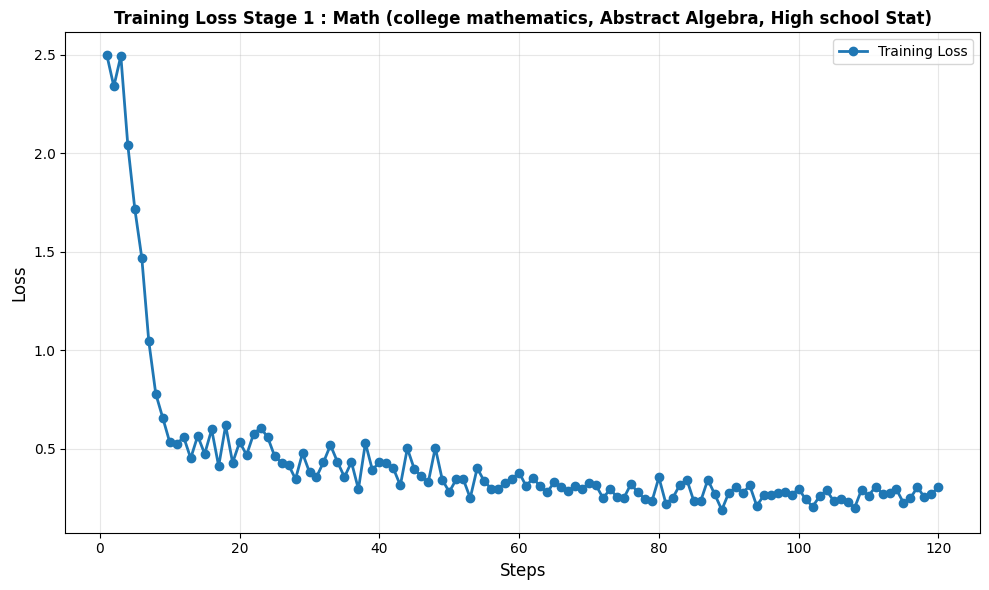

In [42]:
import matplotlib.pyplot as plt

def plot_training_loss(trainer, stage_name, save_path="training_loss.png"):

    log_history = trainer.state.log_history

    train_logs = [log for log in log_history if 'loss' in log]

    eval_logs = [log for log in log_history if 'eval_loss' in log]

    if train_logs:
        train_df = pd.DataFrame(train_logs)

        fig, ax = plt.subplots(figsize=(10, 6))

        if 'loss' in train_df.columns:
            ax.plot(train_df['step'], train_df['loss'],
                   label='Training Loss', marker='o', linewidth=2)
        if eval_logs:
            eval_df = pd.DataFrame(eval_logs)
            if 'eval_loss' in eval_df.columns:
                ax.plot(eval_df['step'], eval_df['eval_loss'],
                       label='Validation Loss', marker='s', linewidth=2, color='orange')

        ax.set_xlabel('Steps', fontsize=12)
        ax.set_ylabel('Loss', fontsize=12)
        ax.set_title(f'Training Loss {stage_name}', fontsize=12, fontweight='bold')
        ax.legend(fontsize=10)
        ax.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        plt.show()

        return train_df, eval_df if eval_logs else None
    else:
        return None, None

train_df_stage1 = plot_training_loss(trainer_stage1,
                                     save_path="loss_plot.png",
                                     stage_name = 'Stage 1 : Math (college mathematics, Abstract Algebra, High school Stat)')

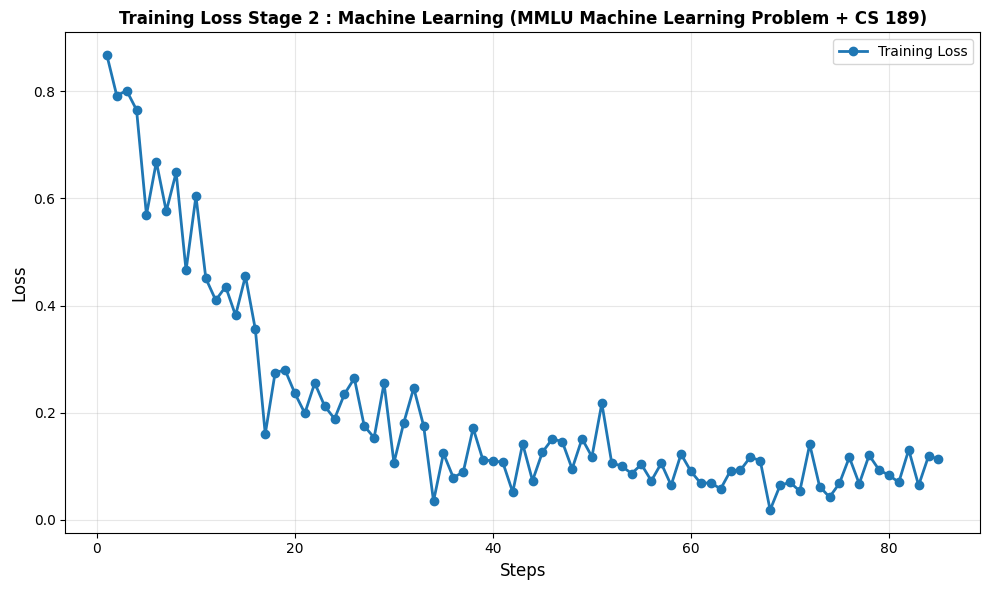

In [43]:
train_df_stage2 = plot_training_loss(trainer_stage2,
                                     save_path="loss_plot.png",
                                     stage_name = 'Stage 2 : Machine Learning (MMLU Machine Learning Problem + CS 189)')

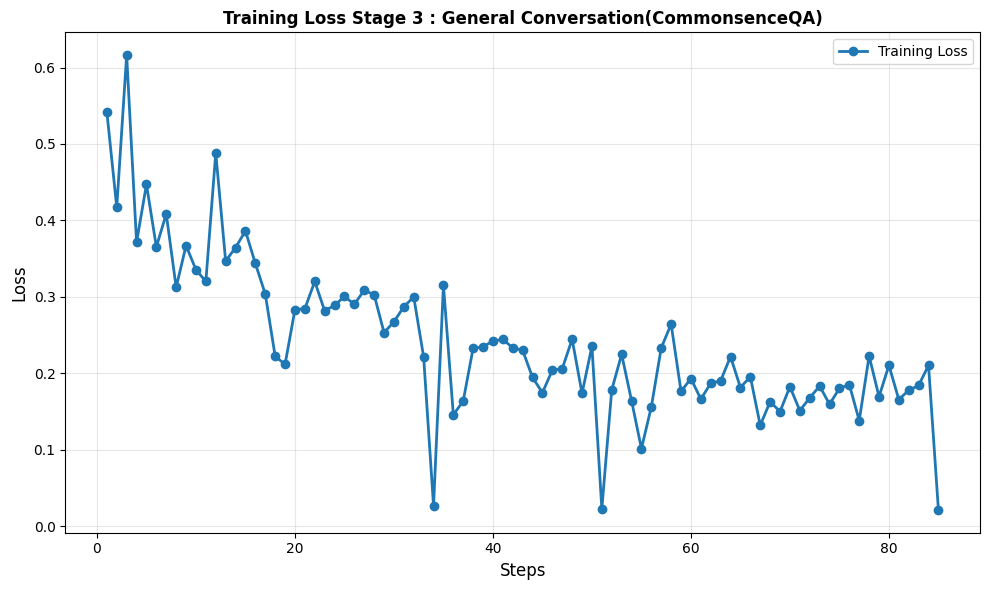

In [44]:
train_df_general, eval_df_general = plot_training_loss(trainer_general,
                                                       save_path="loss_plot.png",
                                                       stage_name = 'Stage 3 : General Conversation(CommonsenceQA)')

### Accuracy Function

In [26]:
from datasets import Features, Value, Sequence, ClassLabel
from collections import Counter
import random

def load_and_convert_mmlu(subject_name="machine_learning", split="test"):
    ds = load_dataset("cais/mmlu", subject_name, split=split)

    def format_to_5choice(example):
        choices = list(example['choices'])

        while len(choices) < 5:
            choices.append("Not applicable")

        answer_idx = example['answer']

        return {
            "question": example['question'],
            "subject": example['subject'],
            "choices": choices[:5],
            "answer": answer_idx
        }

    old_columns = ds.column_names
    ds = ds.map(format_to_5choice, remove_columns=old_columns)

    features = Features({
        'question': Value('string'),
        'subject': Value('string'),
        'choices': Sequence(Value('string')),
        'answer': ClassLabel(names=['A', 'B', 'C', 'D', 'E'])
    })

    return ds.cast(features)


def build_mcq_prompt_from_dataset(row):

    q = str(row["question"]).strip()
    choices = row["choices"]

    options_list = []
    for i, choice in enumerate(choices):
        letter = chr(ord("A") + i)
        options_list.append(f"{letter}. {choice}")
    options_str = "\n".join(options_list)

    prompt = (
        "You are an expert in Machine Learning, Mathematics, and Common Sense reasoning.\n"
        "Your task is to solve the following multiple-choice question systematically.\n\n"
        "Instructions:\n"
        "1. Analyze the Question: Understand the core concept and what is being asked.\n"
        "2. Evaluate Options: Briefly analyze each option to determine why it is correct or incorrect.\n"
        "3. Step-by-Step Reasoning: Think through the logic step-by-step before deciding.\n"
        "4. Final Answer: Output the final answer choice inside a LaTeX box (e.g., \\boxed{A}).\n\n"
        f"Question:\n{q}\n\n"
        f"Options:\n{options_str}\n\n"
        "Let's think step by step.\n"
        "Reasoning:"
    )
    return prompt


def evaluate_model_on_mmlu(
    model,
    tokenizer,
    subject_name="machine_learning",
    split="test",
    max_samples=None,
    max_new_tokens=128,
    save_path="evaluation_results.csv"
):

    mmlu_dataset = load_and_convert_mmlu(subject_name, split=split)

    if max_samples:
        mmlu_dataset = mmlu_dataset.select(range(min(max_samples, len(mmlu_dataset))))

    model.eval()
    results = []

    for idx in range(len(mmlu_dataset)):
        row = mmlu_dataset[idx]

        question_text = row['question']
        choices = row['choices']
        true_answer_idx = row['answer']

        if isinstance(true_answer_idx, int):
            true_answer = chr(ord('A') + true_answer_idx)
        else:
            true_answer = true_answer_idx

        tta_predictions = []

        for aug_idx in range(5):
            user_content = build_mcq_prompt_from_dataset(row)

            messages = [{"role": "user", "content": user_content}]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )

            inputs = tokenizer(prompt, return_tensors="pt").to(model.device)

            with torch.no_grad():
                if aug_idx == 0:
                    do_sample = False
                else:
                    do_sample = True

                outputs = model.generate(
                    **inputs,
                    max_new_tokens=max_new_tokens,
                    do_sample=do_sample,
                    temperature=0.5 if do_sample else None,
                    top_p=0.9 if do_sample else None,
                    pad_token_id=tokenizer.eos_token_id
                )

            gen_tokens = outputs[0][inputs["input_ids"].shape[1]:]
            decoded = tokenizer.decode(gen_tokens, skip_special_tokens=True)

            pred = parse_choice_from_boxed(decoded)

            if pred:
                tta_predictions.append(pred)

        if len(tta_predictions) > 0:
            vote_counts = Counter(tta_predictions)
            final_pred = vote_counts.most_common(1)[0][0]
        else:
            final_pred = 'A'

        is_correct = (final_pred == true_answer)

        results.append({
            'id': f'mmlu_{subject_name}_{idx:05d}',
            'question': question_text[:100] + '...' if len(question_text) > 100 else question_text,
            'True Answer': true_answer,
            'Your Prediction': final_pred,
            'Correct?': 'Yes' if is_correct else 'No',
            'full_question': question_text,
            'decoded_output': decoded[:200] + '...' if len(decoded) > 200 else decoded,
            'tta_votes': dict(vote_counts) if tta_predictions else {},
        })

    results_df = pd.DataFrame(results)

    accuracy = (results_df['Correct?'] == 'Yes').sum() / len(results_df)

    display_df = results_df[['id', 'True Answer', 'Your Prediction', 'Correct?']]
    display_df.to_csv(save_path, index=False)

    full_save_path = save_path.replace('.csv', '_full.csv')
    results_df.to_csv(full_save_path, index=False)

    return results_df, accuracy

## Comparing Baseline and Fine-Tuned Model

In [18]:
baseline_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None,)

finetune_model = AutoModelForCausalLM.from_pretrained(
    OUTPUT_DIR,
    torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
    device_map="auto" if torch.cuda.is_available() else None,)

### Base Model Performance

In [28]:
results_df, accuracy = evaluate_model_on_mmlu(
                           baseline_model,
                           tokenizer,
                           subject_name="machine_learning",
                           max_samples=25,
                           max_new_tokens=200,
                           save_path="evaluation_results.csv")

In [30]:
results_df

,id,question,True Answer,Your Prediction,Correct?,full_question,decoded_output,tta_votes
0,mmlu_machine_learning_00000,Statement 1| Linear regression estimator has t...,D,A,No,Statement 1| Linear regression estimator has t...,To analyze this statement systematically:\n\n#...,"{'A': 4, 'C': 1}"
1,mmlu_machine_learning_00001,Statement 1| RoBERTa pretrains on a corpus tha...,C,A,No,Statement 1| RoBERTa pretrains on a corpus tha...,To determine whether Statement 1 and Statement...,{'A': 5}
2,mmlu_machine_learning_00002,"Statement 1| Support vector machines, like log...",B,A,No,"Statement 1| Support vector machines, like log...","To evaluate the statements and options, let's ...","{'A': 4, 'B': 1}"
3,mmlu_machine_learning_00003,A machine learning problem involves four attri...,D,A,No,A machine learning problem involves four attri...,"To solve this problem, we need to consider how...","{'A': 2, 'C': 1, 'D': 2}"
4,mmlu_machine_learning_00004,"As of 2020, which architecture is best for cla...",A,C,No,"As of 2020, which architecture is best for cla...",To determine the best architecture for classif...,"{'A': 2, 'C': 3}"
5,mmlu_machine_learning_00005,Statement 1| The log-likelihood of the data wi...,B,A,No,Statement 1| The log-likelihood of the data wi...,To analyze this question systematically:\n\n1....,"{'A': 3, 'C': 1, 'D': 1}"
6,mmlu_machine_learning_00006,Let us say that we have computed the gradient ...,A,C,No,Let us say that we have computed the gradient ...,"To understand this problem, let's break down t...","{'C': 2, 'A': 2, 'B': 1}"
7,mmlu_machine_learning_00007,Statement 1| For a continuous random variable ...,B,A,No,Statement 1| For a continuous random variable ...,To analyze this problem systematically:\n\n1. ...,"{'A': 3, 'B': 2}"
8,mmlu_machine_learning_00008,Consider the Bayesian network given below. How...,C,A,No,Consider the Bayesian network given below. How...,To determine how many independent parameters a...,{'A': 5}
9,mmlu_machine_learning_00009,As the number of training examples goes to inf...,A,C,No,As the number of training examples goes to inf...,"To understand this problem, let's break down t...","{'C': 2, 'D': 1, 'A': 1, 'B': 1}"


## Fine-Tuned Model Performance

In [32]:
results_df_fine, accuracy_fine = evaluate_model_on_mmlu(
                           finetune_model,
                           tokenizer,
                           subject_name="machine_learning",
                           max_samples=25,
                           max_new_tokens=200,
                           save_path="evaluation_results.csv")

In [34]:
print('Fine-tuning Accuracy :',f"{accuracy_fine * 100}%")

Fine-tuning Accuracy : 64.0%


In [33]:
results_df_fine

,id,question,True Answer,Your Prediction,Correct?,full_question,decoded_output,tta_votes
0,mmlu_machine_learning_00000,Statement 1| Linear regression estimator has t...,D,B,No,Statement 1| Linear regression estimator has t...,\boxed{B},{'B': 5}
1,mmlu_machine_learning_00001,Statement 1| RoBERTa pretrains on a corpus tha...,C,B,No,Statement 1| RoBERTa pretrains on a corpus tha...,\boxed{B},"{'B': 4, 'A': 1}"
2,mmlu_machine_learning_00002,"Statement 1| Support vector machines, like log...",B,C,No,"Statement 1| Support vector machines, like log...",\boxed{B},"{'C': 3, 'B': 2}"
3,mmlu_machine_learning_00003,A machine learning problem involves four attri...,D,C,No,A machine learning problem involves four attri...,\boxed{C},{'C': 5}
4,mmlu_machine_learning_00004,"As of 2020, which architecture is best for cla...",A,A,Yes,"As of 2020, which architecture is best for cla...",\boxed{A},{'A': 5}
5,mmlu_machine_learning_00005,Statement 1| The log-likelihood of the data wi...,B,B,Yes,Statement 1| The log-likelihood of the data wi...,\boxed{B},"{'B': 4, 'C': 1}"
6,mmlu_machine_learning_00006,Let us say that we have computed the gradient ...,A,A,Yes,Let us say that we have computed the gradient ...,\boxed{A},{'A': 5}
7,mmlu_machine_learning_00007,Statement 1| For a continuous random variable ...,B,B,Yes,Statement 1| For a continuous random variable ...,\boxed{C},"{'B': 3, 'C': 2}"
8,mmlu_machine_learning_00008,Consider the Bayesian network given below. How...,C,C,Yes,Consider the Bayesian network given below. How...,\boxed{C},"{'C': 3, 'B': 1, 'E': 1}"
9,mmlu_machine_learning_00009,As the number of training examples goes to inf...,A,A,Yes,As the number of training examples goes to inf...,\boxed{A},{'A': 5}


## Catastrophic Forgetting
### 1. Baseline Model

In [42]:
results_df, accuracy = evaluate_model_on_mmlu(
                           baseline_model,
                           tokenizer,
                           subject_name="high_school_statistics",
                           max_samples=25,
                           max_new_tokens=200,
                           save_path="evaluation_results.csv")

In [37]:
print('Baseline Accuracy :',f"{accuracy * 100}%")

Baseline Accuracy : 16.0%


In [46]:
results_df

,id,question,True Answer,Your Prediction,Correct?,full_question,decoded_output,tta_votes
0,mmlu_high_school_statistics_00000,The weight of an aspirin tablet is 300 milligr...,B,A,No,The weight of an aspirin tablet is 300 milligr...,"To solve this problem, let's break down the st...",{'A': 5}
1,mmlu_high_school_statistics_00001,The waiting times for a new roller coaster rid...,C,A,No,The waiting times for a new roller coaster rid...,To find the shortest time interval associated ...,{'A': 5}
2,mmlu_high_school_statistics_00002,All of the following statements are true for a...,D,A,No,All of the following statements are true for a...,To determine which statement is true for all d...,"{'A': 4, 'C': 1}"
3,mmlu_high_school_statistics_00003,Which of the following is a true statement abo...,D,B,No,Which of the following is a true statement abo...,To determine which statement is true regarding...,"{'B': 3, 'A': 2}"
4,mmlu_high_school_statistics_00004,An outlier is an observation that,D,A,No,An outlier is an observation that,"To determine the correct answer, let's break d...","{'A': 4, 'D': 1}"
5,mmlu_high_school_statistics_00005,The principal of a school is interested in est...,D,A,No,The principal of a school is interested in est...,To interpret the given 95 percent confidence i...,"{'A': 4, 'B': 1}"
6,mmlu_high_school_statistics_00006,Researchers are conducting an experiment using...,D,A,No,Researchers are conducting an experiment using...,"To analyze this problem systematically, let's ...","{'A': 3, 'B': 2}"
7,mmlu_high_school_statistics_00007,"The mean height of adult men is 70 inches, wit...",D,A,No,"The mean height of adult men is 70 inches, wit...",To determine which individual is more unusuall...,{'A': 5}
8,mmlu_high_school_statistics_00008,Which of the following is not true about t-dis...,C,A,No,Which of the following is not true about t-dis...,To determine which statement is not true about...,"{'A': 4, 'D': 1}"
9,mmlu_high_school_statistics_00009,To study the effect of alcohol on reaction tim...,D,C,No,To study the effect of alcohol on reaction tim...,"To address this question systematically, let's...","{'B': 1, 'A': 1, 'C': 3}"


### 2. Fine-tuned Model

In [43]:
results_df_fine, accuracy_fine = evaluate_model_on_mmlu(
                           finetune_model,
                           tokenizer,
                           subject_name="high_school_statistics",
                           max_samples=25,
                           max_new_tokens=200,
                           save_path="evaluation_results.csv")

In [45]:
results_df_fine

,id,question,True Answer,Your Prediction,Correct?,full_question,decoded_output,tta_votes
0,mmlu_high_school_statistics_00000,The weight of an aspirin tablet is 300 milligr...,B,B,Yes,The weight of an aspirin tablet is 300 milligr...,\boxed{B},{'B': 5}
1,mmlu_high_school_statistics_00001,The waiting times for a new roller coaster rid...,C,D,No,The waiting times for a new roller coaster rid...,\boxed{D},{'D': 5}
2,mmlu_high_school_statistics_00002,All of the following statements are true for a...,D,B,No,All of the following statements are true for a...,\boxed{C},"{'B': 4, 'C': 1}"
3,mmlu_high_school_statistics_00003,Which of the following is a true statement abo...,D,D,Yes,Which of the following is a true statement abo...,\boxed{D},"{'D': 3, 'E': 2}"
4,mmlu_high_school_statistics_00004,An outlier is an observation that,D,D,Yes,An outlier is an observation that,\boxed{D},{'D': 5}
5,mmlu_high_school_statistics_00005,The principal of a school is interested in est...,D,D,Yes,The principal of a school is interested in est...,\boxed{D},{'D': 5}
6,mmlu_high_school_statistics_00006,Researchers are conducting an experiment using...,D,B,No,Researchers are conducting an experiment using...,\boxed{B},"{'B': 4, 'D': 1}"
7,mmlu_high_school_statistics_00007,"The mean height of adult men is 70 inches, wit...",D,E,No,"The mean height of adult men is 70 inches, wit...",\boxed{E},{'E': 5}
8,mmlu_high_school_statistics_00008,Which of the following is not true about t-dis...,C,C,Yes,Which of the following is not true about t-dis...,\boxed{C},{'C': 5}
9,mmlu_high_school_statistics_00009,To study the effect of alcohol on reaction tim...,D,D,Yes,To study the effect of alcohol on reaction tim...,\boxed{D},{'D': 5}
